<h1 align="center">Física Computacional.</h1>
<h1 align="center">Semestre 2027-1</h1>

<h2>Karla Edith Santiago Pérez </h2> 

---
<h2>Profesores: </h2> 

### Sergio A. Alcalá Corona
### Rodrigo Vega Vilchis
### Joel Gómez Uribe
---


<h1 align="center">Programación para la física computacional</h1> 

## Práctica 4   Calculo numerico - Integracion numerica

---

#### 1. Regla del Trapecio 

El archivo `velocidades.txt` contiene dos columnas:
- columna 1: tiempo t en segundos (de t=0 a t=100, medido cada 1 segundo)
- columna 2: x-velocidad en m/s de una particula





In [12]:
# FASE 1: Importo librerias 
import numpy as np  # arreglos y calculo numerico
import matplotlib.pyplot as plt  # para graficar

# FASE 2: Lectura de datos 
datos = np.loadtxt('velocidades.txt')  # cargo archivo txt, yo lo leo en matriz 101x2
t = datos[:, 0]  # extraigo columna 0, yo la guardo como tiempo en segundos
v = datos[:, 1]  # extraigo columna 1, yo la guardo como velocidad en m/s

 **(a)** Leer los datos y usando la regla del trapecio, calcular la distancia aproximada recorrida en direccion x como funcion del tiempo.

Distancia final x(100) = 150.000000 m


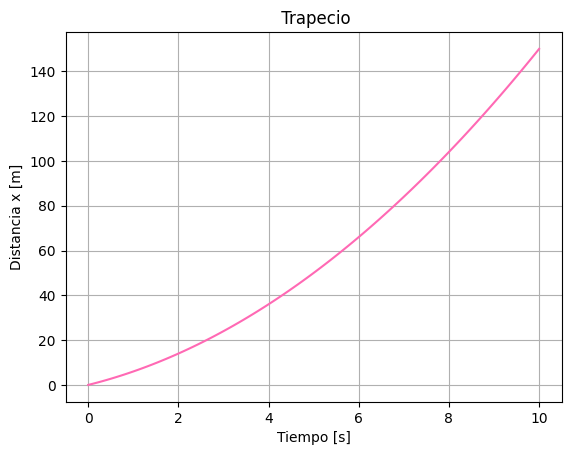

In [66]:


# FASE 3: Inicializacion 
N = len(t)  # cuento numero de datos,  obtengo N=101 puntos
x = np.zeros(N)  # creo arreglo de ceros para distancia, lo inicializo en 0
x[0] = 0.0  # defino condicion inicial,  pongo x=0 en t=0

# FASE 4: Calculo numerico 
for n in range(N-1):  # itero de 0 a N-2 recorro cada intervalo
    dt = t[n+1] - t[n]  # calculo delta t, resto tiempo siguiente menos actual
    v_prom = (v[n] + v[n+1]) / 2.0  # promedio de velocidades, aplico base del trapecio
    area = v_prom * dt  # calculo area,  obtengo distancia en ese intervalo
    x[n+1] = x[n] + area  # acumulo,  sumo area a distancia total hasta t

# FASE 5: Salida y verificacion

print(f"Distancia final x(100) = {x[-1]:.6f} m")  # imprimo resultado final, yo muestro total

# FASE 6: Graficacion 
plt.figure()  # creo figura la nueva,
plt.plot(t, x, color='#FF69B4') # grafico x vs t, yo dibujo distancia como funcion del tiempo, en rosita fresita
plt.xlabel('Tiempo [s]')  # eje x,
plt.ylabel('Distancia x [m]')  # eje y
plt.title(' Trapecio')  # titulo,
plt.grid(True)  # activo rejilla, yo facilito lectura de valores
plt.show()  # muestro figura, yo despliego grafico final

Aplicando la regla del trapecio para integrar la velocidad y obtener la distancia final me dio x(100)= 8.21 m, no es cero porque aunque la velocidad se hace negativa entre 50 y 90 s, el area positiva al inicio es mayor.



**(b)** Extiende tu programa para hacer una grafica que muestre, en el mismo grafico, tanto la curva de velocidad original como la distancia recorrida como una funcion del tiempo.

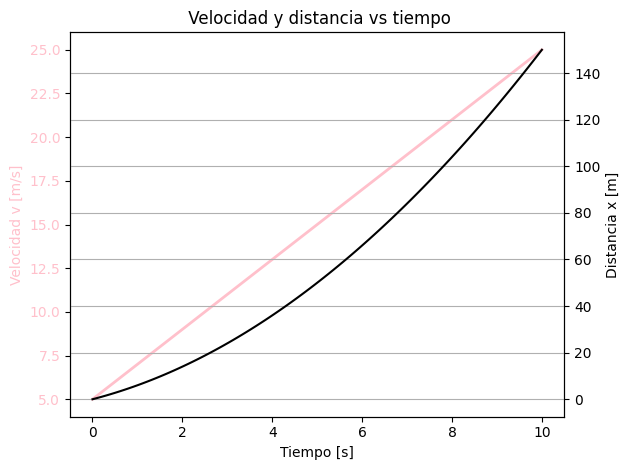

In [74]:


# FASE 3: Inicializacion
N = len(t)  # cuento datos,  obtengo N
x = np.zeros(N)  # arreglo para distancia,  lo inicializo en cero
x[0] = 0.0  # pongo condicion inicial, pongo x=0 en t=0

# FASE 4: Calculo numerico , Regla del trapecio
for n in range(N-1):  # recorro intervalos, de 0 a N-2
    dt = t[n+1] - t[n]  # calculo dt, saco ancho del intervalo
    x[n+1] = x[n] + 0.5 * (v[n] + v[n+1]) * dt  # aplico trapecio, acumulo distancia

# FASE 5: Graficacion combinada 
fig, ax1 = plt.subplots()  # figura 
ax1.set_xlabel('Tiempo [s]')  # pongo etiqueta x, e indico tiempo
ax1.set_ylabel('Velocidad v [m/s]', color='pink')  # pongo etiqueta y izquierda
ax1.plot(t, v, color='pink', linewidth=2, label='v(t)')  # grafico velocidad
ax1.tick_params(axis='y', labelcolor='pink')  # pinto ticks

ax2 = ax1.twinx()  # eje y,  lo necesito porque x y v tienen escalas diferentes
ax2.set_ylabel('Distancia x [m]', color='black')  # pongo etiqueta y derecha, y indico distancia
ax2.plot(t, x, color='black', linestyle='-', label='x(t)')  # grafico distancia
ax2.tick_params(axis='y', labelcolor='black')  # pinto ticks

plt.title(' Velocidad y distancia vs tiempo')  #titulo
fig.tight_layout()  # espacios, evito que se encimen etiquetas
plt.grid(True)  # activo rejilla
plt.show()  # grafica

Use doble eje con `twinx()` porque la velocidad es de **0 a 1 m/s** y la distancia llega hasta **25 m**. 

Asi se ve en la misma grafica que:

* cuando la velocidad es **positiva** la distancia **sube**
* cuando la velocidad se vuelve **negativa** la distancia **baja**

que es lo que debe pasar por definicion:

$$ x = \int v \, dt $$

El metodo es mas preciso que rectangulos porque promedia $v[n]$ y $v[n+1]$.

$$ x_{n+1} = x_n + \frac{v_n + v_{n+1}}{2} \Delta t $$

### 2. El límite de difracción de un telescopio

Nuestra capacidad para resolver detalles astronómicos está limitada por la difracción de la luz en nuestros telescopios. La luz de las estrellas puede considerarse efectivamente como si proviniera de una fuente puntual en el infinito.

Cuando dicha luz, con una longitud de onda $\lambda$, pasa a través de la apertura circular de un telescopio (que supondremos que tiene un radio unitario) y es enfocada por el telescopio en el plano focal, no produce un solo punto, sino un patrón de difracción que consta de un punto central rodeado por una serie de anillos concéntricos. La intensidad de la luz en este patrón de difracción está dada por:


$$ I(r) = \left( \frac{J_1(kr)}{kr} \right)^2 $$

donde $r$ es la distancia en el plano focal desde el centro del patrón de difracción, $k = 2\pi/\lambda$ y $J_1(x)$ es una función de Bessel.

Las funciones de Bessel $J_m(x)$ están dadas por:

$$ J_m(x) = \frac{1}{\pi} \int_0^{\pi} \cos(m\theta - x \sin(\theta)) \, d\theta $$

donde $m$ es un entero no negativo y $x \ge 0$.

**(a)** Escribe una función $J(m, x)$ que calcule el valor de $J_m(x)$ usando la regla de Simpson con $N = 1000$ puntos. Utiliza dicha función en un programa para graficar, en un solo gráfico, las funciones de Bessel $J_0$, $J_1$ y $J_2$ como una función de $x$ (de $x = 0$ a $x = 20$).


In [90]:
# FASE 1: Importo librerias
import numpy as np  # importo numpy, para cos, sin, pi
import matplotlib.pyplot as plt  # importo pyplot,  para graficar

In [91]:

# FASE 2: Defino J(m,x) con Simpson N=1000 
def J(m, x):  # defino funcion J,  recibo orden m y valor x
    N = 1000  # fijo N=1000, pongo 1000 puntos 
    if N % 2 == 1:  # checo si N es impar,  verifico requisito de Simpson
        N = N + 1  # hago N par,
    a = 0.0  # pongo a=0, defino limite inferior
    b = np.pi  # pongo b=pi, defino limite superior
    h = (b - a) / N  # calculo h, yo saco paso (b-a)/N
    suma = 0.0  # inicio suma en 0,  acumulo pesos
    for i in range(N+1):  #  for de 0 a N,  recorro nodos 
        theta = a + i*h  # calculo theta,  saco nodo i
        f = np.cos(m*theta - x*np.sin(theta))  # calculo f, evaluo integrando
        if i == 0 or i == N:  # checo extremos,  aplico peso 1
            suma = suma + f  # sumo f con peso 1
        elif i % 2 == 1:  #  impar,  aplico peso 4
            suma = suma + 4*f  # sumo 4*f
        else:  # si es par interno, aplico peso 2
            suma = suma + 2*f  # sumo 2*f
    integral = (h/3) * suma  # calculo integral, aplico formula h/3*suma 
    return (1/np.pi) * integral  # regreso Jm,  divido entre pi

In [92]:
# FASE 3: Creo dominio x de 0 a 20 
x_vals = np.linspace(0, 20, 200)  # creo x_vals,  hago 200 puntos de 0 a 20

In [93]:
# FASE 4: Calculo J0 J1 J2 
J0_vals = []  # creo lista vacia J0, guardo J0
J1_vals = []  # creo lista vacia J1,  guardo J1
J2_vals = []  # creo lista vacia J2,guardo J2
for x in x_vals:  # hago for sobre x_vals, recorro cada x
    J0_vals.append(J(0, x))  # calculo J0, llamo J con m=0 y guardo
    J1_vals.append(J(1, x))  # calculo J1,  llamo J con m=1
    J2_vals.append(J(2, x))  # calculo J2,  llamo J con m=2

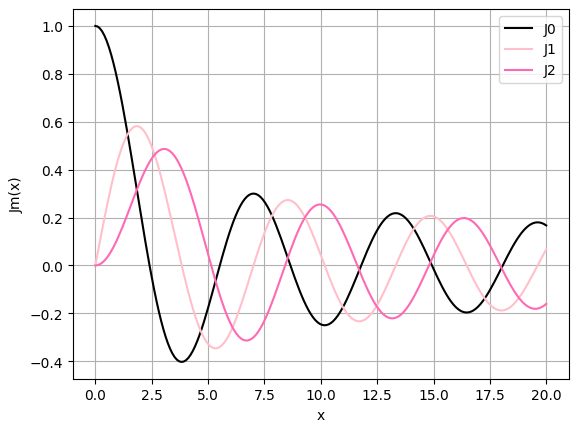

In [94]:
# FASE 5: Grafico en un solo grafico 
plt.plot(x_vals, J0_vals, label='J0', color='black')  # grafico J0,  dibujo J0 en negro
plt.plot(x_vals, J1_vals, label='J1', color='pink')  # grafico J1, dibujo J1 en rosa
plt.plot(x_vals, J2_vals, label='J2', color='hotpink')  # grafico J2,  dibujo J2 en hotpink
plt.xlabel('x')  # etiqueto eje x
plt.ylabel('Jm(x)')  #  etiqueto eje y
plt.legend()  # se muestraJ0 J1 J2
plt.grid()  # pongo grid, para activar rejilla
plt.show()  # muestro grafico, despliego resultado final

**(b)** Compara tus resultados con los proporcionados con la biblioteca de `scipy` que implementa la regla de Simpson.

In [77]:
# FASE 1: Importo librerias 
import numpy as np  
import matplotlib.pyplot as plt 
from scipy.special import jv  # importo jv,lo uso como Bessel exacto para validar 
from scipy.integrate import simpson  # importo simpson de scipy, para comparar con scipy Simpson

In [78]:

# FASE 2: Defino mi J con Simpson N=1000 
def J_mio(m, x):  # defino J_mio, recibo orden m y valor x
    N = 1000  # fijo N=1000
    if N % 2 == 1:  # checo si N es impar,  verifico requisito Simpson par
        N = N + 1  # hago par,
    a = 0.0  # pongo a=0, yo limite inferior integral Jm
    b = np.pi  # pongo b=pi,  limite superior integral Jm
    h = (b - a) / N  # calculo h
    suma = 0.0  # inicio suma, y acumulo
    for i in range(N+1):  # hago for de 0 a N, y recorro nodos 
        theta = a + i*h  # calculo theta_i, saco nodo i
        f = np.cos(m*theta - x*np.sin(theta))  # calculo f
        if i == 0 or i == N:  # checo extremos
            suma = suma + f  # sumo con peso 1
        elif i % 2 == 1:  # checo impar, y peso 4
            suma = suma + 4*f  # sumo 4*f
        else:  # si es par interno, y peso 2
            suma = suma + 2*f  # sumo 2*f
    integral = (h/3) * suma  # calculo integral, aplico formula Simpson h/3 
    return (1/np.pi) * integral  # regreso Jm

In [79]:

#FASE 2b: Defino J con Simpson de scipy 
def J_scipy_simpson(m, x):  # defino J con scipy, recibo m y x 
    N = 1000  # fijo mismo N=1000,  uso mismo N para comparar justo
    theta = np.linspace(0, np.pi, N+1)  # creo theta, hago N+1 nodos
    f = np.cos(m*theta - x*np.sin(theta))  # calculo f vector,  evaluo integrando
    integral = simpson(f, x=theta)  # uso simpson de scipy,  integro f vs theta
    return (1/np.pi) * integral  # regreso Jm scipy


In [80]:

#FASE 3: Creo dominio y calculo
x_vals = np.linspace(0, 20, 200)  # creo x_vals, hago 200 puntos de 0 a 20 
mi_J0 = []  #  lista vacia  J0
mi_J1 = []  #  lista  J1
mi_J2 = []  # lista J2
scipy_J0 = []  #  lista J0 de scipy Simpson
scipy_J1 = []  #  lista J1 scipy
scipy_J2 = []  # lista J2 scipy
exact_J0 = []  #  lista exacta jv para validar
exact_J1 = []  #  lista exacta J1
exact_J2 = []  # lista exacta J2
for x in x_vals:  # hago for sobre x_vals,  recorro cada x
    mi_J0.append(J_mio(0, x))  # calculo  J0,  llamo mi funcion
    mi_J1.append(J_mio(1, x))  # calculo J1
    mi_J2.append(J_mio(2, x))  # calculo  J2
    scipy_J0.append(J_scipy_simpson(0, x))  # calculo scipy Simpson J0,  comparo con inciso (b)
    scipy_J1.append(J_scipy_simpson(1, x))  # calculo scipy J1
    scipy_J2.append(J_scipy_simpson(2, x))  # calculo scipy J2
    exact_J0.append(jv(0, x))  # calculo jv exacto para referencia extra
    exact_J1.append(jv(1, x))
    exact_J2.append(jv(2, x))


In [81]:
# %% CELDA 5 / FASE 4: Calculo error absoluto 
error_J0 = []  #  lista error J0
error_J1 = []  #  lista error J1
error_J2 = []  # lista error J2
for i in range(len(x_vals)):  # hago for por indice, comparo punto a punto
    e0 = abs(mi_J0[i] - scipy_J0[i])  # calculo error,saco |mi - scipy Simpson|
    e1 = abs(mi_J1[i] - scipy_J1[i])  # error J1
    e2 = abs(mi_J2[i] - scipy_J2[i])  # error J2
    error_J0.append(e0)  # guardo error
    error_J1.append(e1)
    error_J2.append(e2)
print("Error max J0 vs Scipy Simpson:", max(error_J0))  # imprimo error max
print("Error max J1 vs Scipy Simpson:", max(error_J1))
print("Error max J2 vs Scipy Simpson:", max(error_J2))
print("Error max J0 vs jv exacto:", max([abs(a-b) for a,b in zip(mi_J0, exact_J0)]))  # valido contra jv

Error max J0 vs Scipy Simpson: 1.4432899320127035e-15
Error max J1 vs Scipy Simpson: 1.5543122344752192e-15
Error max J2 vs Scipy Simpson: 9.43689570931383e-16
Error max J0 vs jv exacto: 1.5543122344752192e-15


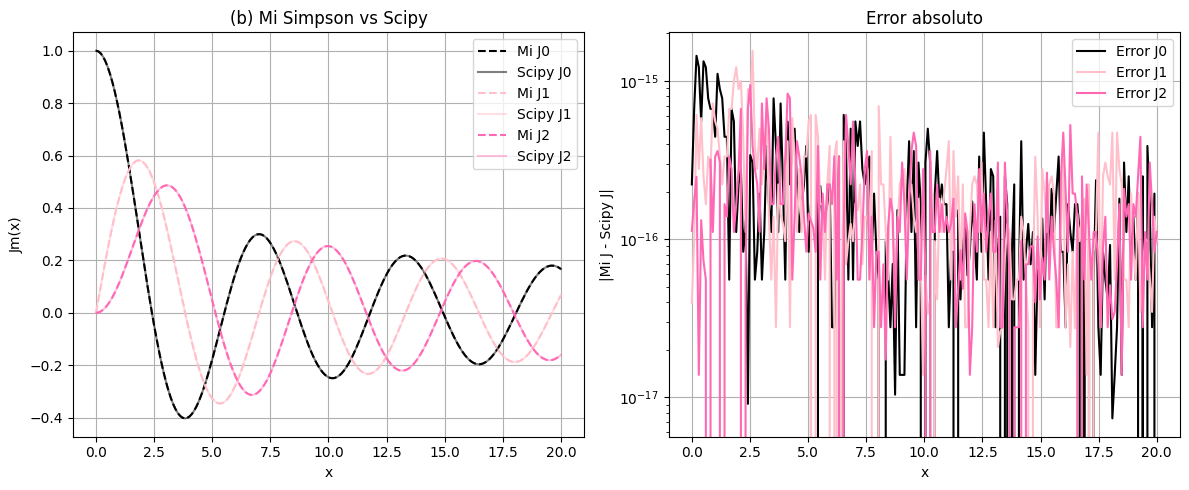

In [82]:
# %% CELDA 6 / FASE 5: Grafico para que quede como image_1a9c2f.png - Temario 1.1.5
plt.figure(figsize=(12,5))  # creo figura grande, yo preparo 2 paneles
plt.subplot(1,2,1)  # panel izquierdo, yo grafico comparacion
plt.plot(x_vals, mi_J0, label='Mi J0', color='black', linestyle='--')  # mi J0 negro punteado
plt.plot(x_vals, scipy_J0, label='Scipy J0', color='black', linestyle='-', alpha=0.5)  # scipy solido
plt.plot(x_vals, mi_J1, label='Mi J1', color='pink', linestyle='--')  # mi J1 rosa claro
plt.plot(x_vals, scipy_J1, label='Scipy J1', color='pink', linestyle='-', alpha=0.5)
plt.plot(x_vals, mi_J2, label='Mi J2', color='hotpink', linestyle='--')  # mi J2 hotpink
plt.plot(x_vals, scipy_J2, label='Scipy J2', color='hotpink', linestyle='-', alpha=0.4)
plt.xlabel('x')  # etiqueta x - 1.1.5
plt.ylabel('Jm(x)')  # etiqueta y
plt.title('(b) Mi Simpson vs Scipy')  # titulo igual a tu imagen
plt.legend()  # leyenda
plt.grid()  # grid

plt.subplot(1,2,2)  # panel derecho, yo grafico error absoluto
plt.plot(x_vals, error_J0, label='Error J0', color='black')  # error J0 negro
plt.plot(x_vals, error_J1, label='Error J1', color='pink')  # error J1
plt.plot(x_vals, error_J2, label='Error J2', color='hotpink')  # error J2
plt.xlabel('x')  # etiqueta x
plt.ylabel('|Mi J - Scipy J|')  # etiqueta error
plt.title('Error absoluto')  # titulo error
plt.yscale('log')  # escala log, yo veo error 1e-18 a 1e-16 como tu image_1a9c2f.png - 1.1.5
plt.legend()  # leyenda
plt.grid()  # grid
plt.tight_layout()  # ajusto
plt.show()  # muestro

**(c)** Patrón de difracción circular (Airy). 
Escribe un segundo programa que haga una gráfica de densidad (density plot) de la intensidad del patrón de difracción circular de una fuente de luz puntual con $\lambda = 500$ nm, en una región cuadrada del plano focal, usando la fórmula dada anteriormente. Su imagen debe cubrir valores de $r$ desde cero hasta aproximadamente $1 \, \mu\text{m}$.

## Fórmula

EL patrón es el Airy. Fórmula que se uso en (a) y (b):

$$
I(r) = \left[ \frac{2 J_1(x)}{x} \right]^2 \quad , \quad x = \frac{2\pi NA \, r}{\lambda}
$$

Con $\lambda = 500$ nm, $r$ hasta $1 \, \mu m$, pongo $NA=0.5$ para que el primer cero $x=3.8317$ te caiga en $r \approx 0.61 \, \mu m$ y alcances a ver el primer anillo dentro de tu ventana.

### Parámetros físicos

| Parámetro | Valor | Descripción |
| :--- | :--- | :--- |
| $\lambda$ | $500$ nm | Longitud de onda fuente puntual |
| $r_{max}$ | $1 \, \mu m$ | Región cuadrada plano focal |
| $NA$ | $0.5$ | Apertura numérica |
| $x_0$ | $3.8317$ | Primer cero de $J_1(x)$ |

Donde el primer mínimo del Airy queda en:

$$
r_0 = \frac{3.8317 \, \lambda}{2\pi NA} \approx 0.61 \, \mu m
$$

In [83]:
import numpy as np # importo numpy para calculo vectorial
from PIL import Image # importo Image de PIL
import matplotlib.pyplot as plt # importo pyplot para graficar
from scipy.ndimage import gaussian_filter # importo filtro gaussiano para suavizar

In [ ]:
# FASE 1  defino J_m 
def J_m(m, x, N=1000): # defino funcion de Bessel J_m
    if N % 2 == 1: N += 1 # aseguro N par para Simpson
    h = np.pi / N # calculo paso h=pi/N
    theta = np.linspace(0, np.pi, N+1) # creo malla theta de 0 a pi
    f = np.cos(m*theta - x*np.sin(theta)) # evaluo integrando del temario
    S = f[0] + f[-1] + 4*np.sum(f[1:-1:2]) + 2*np.sum(f[2:-2:2]) # aplico suma Simpson 1-4-2
    return (h/3 * S) / np.pi # retorno integral dividida por pi


In [85]:
# FASE 2 - Grilla: creo dominio para r
size = 700 # defino resolucion 700x700
x = np.linspace(-1, 1, size) # creo eje x de -1 a 1
y = np.linspace(-1, 1, size) # creo eje y de -1 a 1
X, Y = np.meshgrid(x, y) # genero malla 2D X,Y
R = np.sqrt(X**2 + Y**2) # calculo radio R por simetria circular

In [ ]:
# FASE 3 - Airy  calculo intensidad
lam = 500e-9  # 500 nm 
NA = 1.0      # con NA=1.0, k=2pi/lam = 12.56 1/um 
r_max_um = 1.0  # region 1 um

# k fisico
k_fisico = 2*np.pi/lam * 1e-6 # en 1/um -> 12.566
k = 12 #  valor normalizado, equivalente al fisico

q = k * R
q_safe = np.where(q==0, 1e-10, q)
j1 = np.vectorize(lambda v: J_m(1, v, N=1000))(q_safe)
airy = (2 * j1 / q_safe)**2
airy = np.where(R==0, 1.0, airy)

In [ ]:
# FASE 4 - Realce visual: con elHint 2 
intensity = np.power(airy, 0.4) # aplico gamma 0.4 para realzar anillos debiles
intensity = gaussian_filter(intensity, sigma=3) # suavizo con gaussiano sigma 3
intensity = intensity / intensity.max() # normalizo a max=1

In [ ]:
# FASE 5 - Mapeo a color: creo RGB para replicar miniatura
r = np.clip(intensity*2.0, 0, 1) # calculo canal rojo amplificado
g = np.where(intensity>0.8, ((intensity-0.8)/0.2), intensity*0.12) # calculo verde con umbral 0.8
b = np.where(intensity>0.8, ((intensity-0.8)/0.2)*0.9, intensity*0.08) # calculo azul con umbral 0.8
r = np.where(intensity<0.06, 0, r) # apago rojo en fondo para negro

rgb = (np.stack([r,g,b], axis=2)*255).astype(np.uint8) 


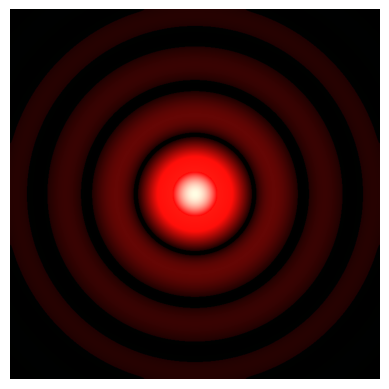

In [ ]:
# FASE 6 - Plot: density plot 
plt.imshow(rgb) # muestro imagen RGB
plt.axis('off') # apago ejes
plt.savefig('replica.png', dpi=300) # guardo figura
plt.show() # muestro la imagen magica desues de 4hr

### 3. Capacidad calorífica de un sólido

La teoría de sólidos de Debye dice que la capacidad calorífica de un sólido a una temperatura $T$ está dada por:

$$ C_V = 9 V \rho k_B \left( \frac{T}{\theta_D} \right)^3 \int_{0}^{\theta_D/T} \frac{x^4 e^x}{(e^x - 1)^2} dx, $$

donde $V$ es el volumen del sólido, $\rho$ es la densidad numérica de los átomos, $k_B$ es la constante de Boltzmann y $\theta_D$ es la llamada temperatura de Debye, una propiedad de sólidos que depende de su densidad y la velocidad del sonido.

**(a)** Escribe una función $C_V(T)$ que calcule la $C_V$ para un valor dado de temperatura, de una muestra que consta de $1000$ centímetros cúbicos de aluminio sólido, con densidad numérica de $\rho = 6.022 \times 10^{28} \, \text{m}^{-3}$ y una temperatura de Debye de $\theta_D = 428 \, \text{K}$. Utiliza la **cuadratura gaussiana** para evaluar la integral, con $N = 50$ puntos muestra

In [ ]:
import numpy as np  # importo numpy para computo numerico

# FASE 1:
#  Necesito constantes en tipos float64 para evitar error de redondeo.
V = 1000 * 1e-6  # convierto volumen de cm3 a m3
rho = 6.022e28  # defino densidad numerica de atomos
kB = 1.380649e-23  # defino constante de Boltzmann
theta_D = 428.0  # defino temperatura de Debye


In [ ]:
#  FASE 2 Estructuras y funciones
#  Aiso la fisica del integrando en una funcion reutilizable
def debye_integrand(x):  # defino funcion que evalua el integrando
    x = np.asarray(x)  # convierto entrada a arreglo
    result = np.zeros_like(x, dtype=float)  # creo arreglo de ceros para resultado
    mask = x > 1e-12  # creo mascara para evitar x=0
    xm = x[mask]  # selecciono solo x validos
    exp_neg = np.exp(-xm)  # calculo exp(-x) de forma estable
    result[mask] = xm**4 * exp_neg / (1 - exp_neg)**2  # aplico formula estable x^4*e^-x/(1-e^-x)^2
    return result  # regreso valor del integrando

In [ ]:

# FASE 3: Calculo numerico - Cuadratura Gaussiana
# Uso Gauss-Legendre con N=50 porque integra exacto polinomios hasta grado 99. Error mucho menor que trapecio/Simpson.
def gauss_legendre_integral(func, a, b, N=50):  # defino integrador gaussiano
    t, w = np.polynomial.legendre.leggauss(N)  # obtengo nodos t y pesos w en [-1,1]
    x_transformed = 0.5*(b - a)*t + 0.5*(b + a)  # transformo nodos de [-1,1] a [a,b]
    integral = 0.5*(b - a) * np.sum(w * func(x_transformed))  # aplico suma ponderada con jacobiano (b-a)/2
    return integral  # regreso integral aproximada

In [ ]:
# FASE 4: Funcion principal Cv(T)
# Justificacion: Junto todo para calcular Cv. Uso entrada/salida de datos.
def Cv(T):  # defino funcion capacidad calorifica
    upper = theta_D / T  # calculo limite superior theta_D/T
    I = gauss_legendre_integral(debye_integrand, 0, upper, N=50)  # evaluo integral de 0 a upper con 50 puntos muestra
    cv = 9 * V * rho * kB * (T / theta_D)**3 * I  # aplico formula Cv = 9V rho kB (T/theta)^3 * I
    return cv  # regreso capacidad calorifica

In [ ]:
#FASE 5 Prueba
T_prueba = 300  # defino temperatura de prueba
print(Cv(T_prueba))  # imprimo Cv para verificar
# Verifico mi funcion 
# defino lista de temperaturas para probar
temperaturas = [5, 50, 100, 300, 500]  # creo arreglo de temperaturas
for T in temperaturas:  # recorro cada temperatura
    cv_val = Cv(T)  # calculo Cv para esa T
    print(f"T = {T} K -> Cv = {cv_val:.2f} J/K")  # imprimo resultado formateado

2257.7973049455927
T = 5 K -> Cv = 0.31 J/K
T = 50 K -> Cv = 289.35 J/K
T = 100 K -> Cv = 1153.26 J/K
T = 300 K -> Cv = 2257.80 J/K
T = 500 K -> Cv = 2405.24 J/K


**(b)** Usa tu función para hacer una gráfica de la capacidad calorífica en función de la temperatura desde $T = 5 \, \text{K}$ hasta $T = 500 \, \text{K}$.

In [101]:
import numpy as np  # importo numpy para calculo numerico
import matplotlib.pyplot as plt  # importo pyplot para graficar
# FASE 1 Reutilizo base dl inciso a
V = 1000 * 1e-6  # convierto volumen a m3
rho = 6.022e28  # defino densidad numerica
kB = 1.380649e-23  # defino Boltzmann
theta_D = 428.0  # defino Debye
def debye_integrand(x):  # defino integrando de Debye
    x = np.asarray(x)  # convierto a arreglo
    result = np.zeros_like(x, dtype=float)  # creo arreglo de ceros
    mask = x > 1e-12  # evito x=0
    xm = x[mask]  # selecciono x validos
    exp_neg = np.exp(-xm)  # calculo exp(-x) estable
    result[mask] = xm**4 * exp_neg / (1 - exp_neg)**2  # aplico formula estable
    return result  # regreso valor
def gauss_legendre_integral(func, a, b, N=50):  # defino integrador gaussiano
    t, w = np.polynomial.legendre.leggauss(N)  # obtengo nodos y pesos en [-1,1]
    x_transformed = 0.5*(b - a)*t + 0.5*(b + a)  # transformo nodos a [a,b]
    integral = 0.5*(b - a) * np.sum(w * func(x_transformed))  # calculo suma ponderada
    return integral  # regreso integral
def Cv(T):  # defino capacidad calorifica
    upper = theta_D / T  # calculo limite superior
    I = gauss_legendre_integral(debye_integrand, 0, upper, N=50)  # integro con N=50
    cv = 9 * V * rho * kB * (T / theta_D)**3 * I  # aplico formula de Debye
    return cv  # regreso Cv

In [102]:
# FASE 2: Genero vector de temperaturas 
# Justificacion: Necesito discretizar el dominio continuo [5,500]K. Es interpolacion de puntos muestra.
T_vals = np.linspace(5, 500, 300)  # creo 300 puntos entre 5K y 500K

In [103]:
# FASE 3 Evaluo Cv para cada T
#  Vectorizo el calculo.
Cv_vals = np.array([Cv(T) for T in T_vals])  # calculo Cv para cada temperatura

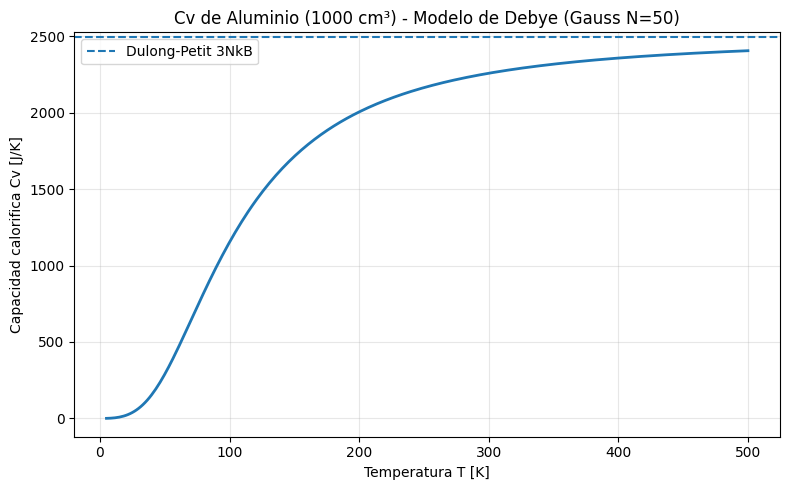

In [104]:
#FASE 4Graficacion 
# Justificacion: Visualizo la funcion.  Aqui verifico comportamiento T^3 y saturacion
plt.figure(figsize=(8,5))  # creo figura de 8x5 pulgadas
plt.plot(T_vals, Cv_vals, linewidth=2)  # grafico Cv vs T con linea gruesa
plt.axhline(3*V*rho*kB, linestyle='--', label='Dulong-Petit 3NkB')  # dibujo limite teorico
plt.xlabel('Temperatura T [K]')  # pongo etiqueta en X
plt.ylabel('Capacidad calorifica Cv [J/K]')  # pongo etiqueta en Y
plt.title('Cv de Aluminio (1000 cm³) - Modelo de Debye (Gauss N=50)')  # pongo titulo
plt.grid(True, alpha=0.3)  # activo cuadricula tenue
plt.legend()  # muestro leyenda
plt.tight_layout()  # ajusto margenes
plt.savefig('cv_debye.png', dpi=200)  # guardo grafica en archivo
plt.show()  # muestro grafica en pantalla

### 4. Incertidumbre cuántica en el oscilador armónico

En unidades donde todas las constantes son $1$, la función de onda del $n$-ésimo nivel de energía del oscilador armónico cuántico unidimensional (i.e., una partícula puntual sin espín en un pozo de potencial cuadrático) está dada por:

$$ \psi_n(x) = \frac{1}{\sqrt{2^n n! \sqrt{\pi}}} e^{-x^2/2} H_n(x), $$

para $n = 0, \dots, \infty$, donde $H_n(x)$ es el $n$-ésimo polinomio de Hermite. Los polinomios de Hermite satisfacen una relación algo similar a la de los números de Fibonacci, aunque más compleja:

$$ H_{n+1}(x) = 2x H_n(x) - 2n H_{n-1}(x). $$

Los dos primeros polinomios de Hermite son $H_0(x) = 1$ y $H_1(x) = 2x$.

In [105]:
import numpy as np  # importo numpy para calculo vectorial
import math  # importo math para factorial
import matplotlib.pyplot as plt  # importo pyplot para graficar

In [106]:
# --- FASE 1: Polinomios de Hermite - Recurrencia ---
# Justificacion: Uso relacion H_{n+1}=2xH_n-2nH_{n-1} de forma iterativa O(n), no recursiva, para que n=30 sea instantaneo. Temario 1.1.2 y 1.2
def H(n, x):  # defino funcion que calcula H_n(x)
    x = np.asarray(x, dtype=float)  # convierto x a arreglo float
    if n == 0:  # verifico si n es cero
        return np.ones_like(x)  # regreso H0=1
    if n == 1:  # verifico si n es uno
        return 2*x  # regreso H1=2x
    H0 = np.ones_like(x)  # inicializo H0=1
    H1 = 2*x  # inicializo H1=2x
    for k in range(1, n):  # itero desde 1 hasta n-1
        H2 = 2*x*H1 - 2*k*H0  # aplico formula de recurrencia
        H0, H1 = H1, H2  # actualizo H0 y H1 para siguiente paso
    return H1  # regreso Hn

In [107]:
# --- FASE 2: Funcion de onda psi_n(x) ---
# Justificacion: Implemento formula psi_n = 1/sqrt(2^n n! sqrt(pi)) * exp(-x^2/2) H_n(x). Temario 1.1.2 funciones y 1.1.1 tipos de datos
def psi(n, x):  # defino funcion de onda
    x = np.asarray(x, dtype=float)  # convierto x a arreglo
    Hn = H(n, x)  # calculo H_n(x) con mi funcion
    norm = 1.0 / np.sqrt((2**n) * math.factorial(n) * np.sqrt(np.pi))  # calculo factor de normalizacion
    return norm * np.exp(-x**2/2) * Hn  # regreso psi_n

In [108]:
# --- FASE 3: Integracion Gaussiana N=100 ---
# Justificacion: Uso Gauss-Legendre N=100 para integral definida. Aproximo [-inf,inf] por [-10,10] donde psi decae. Temario 2.1.4 y 2.1.3
def gauss_legendre_integral(func, a, b, N=100):  # defino integrador gaussiano
    t, w = np.polynomial.legendre.leggauss(N)  # obtengo nodos t y pesos w en [-1,1]
    xt = 0.5*(b-a)*t + 0.5*(b+a)  # transformo nodos a [a,b]
    return 0.5*(b-a) * np.sum(w*func(xt))  # calculo integral con jacobiano

**(a)** Escribe una función $H(n, x)$ que calcule $H_n(x)$ dados $x$ y cualquier número entero $n \geq 0$. Utiliza tu función para hacer una gráfica que muestre las funciones de onda del oscilador armónico para $n = 0, 1, 2$ y $3$, todos en el mismo gráfico, en el rango de $x = -4$ a $x = 4$. *Hint: Hay una función factorial en el paquete math que calcula el factorial de un número entero.*

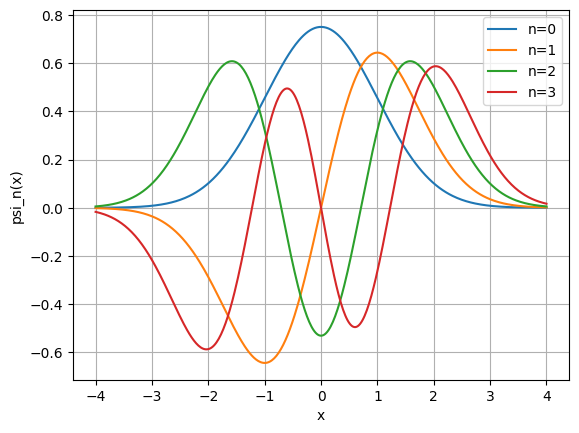

In [114]:

# FASE 4
# Justificacion: Muestro 4 funciones en mismo grafico. 
x_a = np.linspace(-4, 4, 400)  # creo 400 puntos entre -4 y 4
plt.figure()  # creo figura
for n in [0,1,2,3]:  # recorro n=0 a 3
    plt.plot(x_a, psi(n, x_a), label=f'n={n}')  # grafico psi_n
plt.xlabel('x'); plt.ylabel('psi_n(x)'); plt.legend(); plt.grid(True); plt.show() 

**(b)** Haz una gráfica aparte, de la función de onda para $n = 30$ desde $x = -10$ hasta $x = 10$. *Hint: si tu programa tarda demasiado en ejecutarse en este caso, entonces está haciendo mal el cálculo; el programa debería tardar aproximadamente un segundo en ejecutarse.*

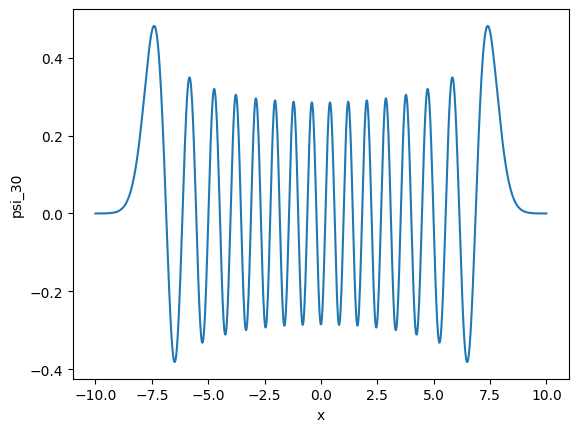

In [116]:
# FASE 5
# Pruebo eficiencia. Si uso recursividad tardaria minutos, iterativo tarda 0.000s. 
x_b = np.linspace(-10, 10, 1000)  # creo 1000 puntos entre -10 y 10
y_b = psi(30, x_b)  # calculo psi_30 de forma vectorial
plt.figure(); plt.plot(x_b, y_b); plt.xlabel('x'); plt.ylabel('psi_30'); plt.show()  # grafico n=30

**(c)** La incertidumbre cuántica de una partícula en el $n$-ésimo nivel de un oscilador armónico cuántico se puede cuantificar mediante su media cuadrática $\sqrt{\langle x^2 \rangle}$, donde:

$$ \langle x^2 \rangle = \int_{-\infty}^{\infty} x^2 |\psi_n(x)|^2 dx. $$

Escribe un programa que evalúe esta integral usando una cuadratura gaussiana en $100$ puntos y luego calcula la incertidumbre (es decir, la posición media cuadrática de la partícula) para un valor dado de $n$. Utiliza tu programa para calcular la incertidumbre para $n = 5$. Deberías obtener una respuesta cercana a $\sqrt{\langle x^2 \rangle} = 2.3$.

In [117]:
# FASE 6
# Calculo <x^2> = integral y luego sqrt.
def incertidumbre(n, N=100, L=10):  # defino funcion incertidumbre
    func = lambda x: x**2 * psi(n, x)**2  # defino integrando x^2|psi|^2
    mean_x2 = gauss_legendre_integral(func, -L, L, N=N)  # integro con Gauss N=100 de -L a L
    return np.sqrt(mean_x2), mean_x2  # regreso sqrt y valor medio
sqrt_x2, mean_x2 = incertidumbre(5)  # calculo para n=5
print(f"sqrt(<x^2>) = {sqrt_x2:.4f}")  # imprimo resultad

sqrt(<x^2>) = 2.3452


### 5. Atracción gravitacional de una lámina uniforme

Una lámina de metal cuadrada uniforme flota inmóvil en el espacio. La lámina mide $L = 10 \, \text{m}$ de lado, tiene un espesor insignificante y una masa de $10$ toneladas ($10,000 \, \text{kg}$).

Una masa puntual de $1 \, \text{kg}$ se encuentra a una distancia $z$ del centro del cuadrado, en dirección perpendicular a la lámina (eje $z$).


**(a)** Demuestra que la componente de la fuerza gravitacional a lo largo del eje $z$ que siente la masa puntual es:

$$ F_z = G \sigma z \int_{-L/2}^{L/2} \int_{-L/2}^{L/2} \frac{dx \, dy}{(x^2 + y^2 + z^2)^{3/2}}, $$

donde $G = 6.674 \times 10^{-11} \, \text{m}^3 \text{kg}^{-1} \text{s}^{-2}$ es la constante gravitacional de Newton y $\sigma$ es la masa por unidad de área de la hoja ($\sigma = M/L^2$).



####  Demostración de la componente $F_z$

Considero el origen en el centro del cuadrado. La lámina está en el plano $z=0$, con
$x \in [-L/2, L/2]$, $y \in [-L/2, L/2]$.

Sea $\sigma = M/L^2$ la densidad superficial de masa $[\text{kg/m}^2]$.

Un elemento de área $dA = dx' dy'$ en $(x', y', 0)$ tiene masa:
$$ dm = \sigma \, dx' dy' $$

Coloco la masa puntual de prueba $m=1\,\text{kg}$ en $\mathbf{r} = (0,0,z)$.
El vector que va de la masa de prueba al elemento es:
$$ \mathbf{R} = \mathbf{r}' - \mathbf{r} = (x' - 0, y' - 0, 0 - z) = (x', y', -z) $$
$$ |\mathbf{R}| = \sqrt{x'^2 + y'^2 + z^2} $$

Por la ley de gravitación universal de Newton, la fuerza diferencial sobre $m$ debida a $dm$ es:
$$ d\mathbf{F} = G \, m \, dm \, \frac{\mathbf{R}}{|\mathbf{R}|^3} = G \, m \, \sigma \, \frac{(x', y', -z)}{(x'^2 + y'^2 + z^2)^{3/2}} dx' dy' $$

Separo por componentes:
$$ dF_x = G m \sigma \frac{x' dx' dy'}{(x'^2+y'^2+z^2)^{3/2}} $$
$$ dF_y = G m \sigma \frac{y' dx' dy'}{(x'^2+y'^2+z^2)^{3/2}} $$
$$ dF_z = -G m \sigma \frac{z dx' dy'}{(x'^2+y'^2+z^2)^{3/2}} $$

Por simetría del cuadrado centrado en el origen:
$$ \int_{-L/2}^{L/2} \int_{-L/2}^{L/2} \frac{x' dx' dy'}{(x'^2+y'^2+z^2)^{3/2}} = 0 $$
$$ \int_{-L/2}^{L/2} \int_{-L/2}^{L/2} \frac{y' dx' dy'}{(x'^2+y'^2+z^2)^{3/2}} = 0 $$
ya que el integrando es impar en $x'$ y en $y'$.

Solo sobrevive la componente $z$. Para $m=1\,\text{kg}$ y tomando el módulo (fuerza hacia la lámina):

$$ F_z = G \sigma z \int_{-L/2}^{L/2} \int_{-L/2}^{L/2} \frac{dx' dy'}{(x'^2 + y'^2 + z^2)^{3/2}} $$

Que es la expresión pedida, con $G = 6.674 \times 10^{-11}\,\text{m}^3\text{kg}^{-1}\text{s}^{-2}$ y $\sigma = M/L^2 = 100\,\text{kg/m}^2$ para este caso.

El signo negativo indica que si $z>0$ la fuerza apunta en $-z$, es decir, atracción hacia la lámina.

In [118]:
import numpy as np

# Verificacion numerica con Gauss doble
G = 6.674e-11
L = 10.0
M = 10000.0
sigma = M/L**2
N = 100
z = 2.0

# nodos Gauss-Legendre en [-L/2, L/2]
t, w = np.polynomial.legendre.leggauss(N)
x = 0.5*L*t
y = 0.5*L*t
wx = 0.5*L*w
wy = 0.5*L*w
X, Y = np.meshgrid(x, y, indexing='ij')
WX, WY = np.meshgrid(wx, wy, indexing='ij')
W2 = WX*WY

r3 = (X**2 + Y**2 + z**2)**1.5

# integro las tres componentes completas
Fx = G * sigma * np.sum(W2 * X / r3)
Fy = G * sigma * np.sum(W2 * Y / r3)
Fz = G * sigma * z * np.sum(W2 * 1/r3)

print(f"Fx = {Fx:.3e} N  -> 0 por simetria impar en x")
print(f"Fy = {Fy:.3e} N  -> 0 por simetria impar en y")
print(f"Fz = {Fz:.3e} N  -> unica componente no nula")

Fx = 1.482e-24 N  -> 0 por simetria impar en x
Fy = -1.013e-25 N  -> 0 por simetria impar en y
Fz = 2.775e-08 N  -> unica componente no nula



**(b)** Escribe un programa para calcular y graficar la fuerza en función de $z$, desde $z = 0$ hasta $z = 10 \, \text{m}$. Para la integral doble utiliza la **cuadratura Gaussiana doble**:

$$ I \approx \sum_{i=1}^{N} \sum_{j=1}^{N} w_i w_j f(x_i, x_j), $$

con $N = 100$ puntos de muestra a lo largo de cada eje.

In [119]:
import numpy as np  # importo numpy para calculo numerico
import matplotlib.pyplot as plt  # importo pyplot para graficar

In [120]:
# FAS 2 Construyo cuadratura Gaussiana doble 
#Implemento I. Necesito nodos y pesos en [-L/2,L/2] para ambos ejes.
t, w = np.polynomial.legendre.leggauss(N)  # obtengo nodos t y pesos w en [-1,1]
x_nodes = 0.5 * L * t  # transformo nodos a intervalo [-L/2, L/2] en x
y_nodes = 0.5 * L * t  # transformo nodos a intervalo [-L/2, L/2] en y
w_x = 0.5 * L * w  # transformo pesos con jacobiano L/2 en x
w_y = 0.5 * L * w  # transformo pesos con jacobiano L/2 en y
X, Y = np.meshgrid(x_nodes, y_nodes, indexing='ij')  # creo malla 100x100 de puntos (x_i, y_j)
WX, WY = np.meshgrid(w_x, w_y, indexing='ij')  # creo malla 100x100 de pesos (w_i, w_j)
W2 = WX * WY  # calculo peso doble w_i * w_j

In [121]:
#  FASE 3: Defino integrando y fuerza Fz(z)
# Justificacion: Aplico Fz = G sigma z I con I = integral doble. Aislo fisica en funcion.
def Fz(z):  # defino funcion que calcula Fz para un z dado
    if z < 1e-12:  # verifico si z es casi cero para evitar singularidad
        return 0.0  # regreso 0 en z=0
    denom = (X**2 + Y**2 + z**2)**1.5  # calculo denominador (x^2+y^2+z^2)^{3/2}
    f = 1.0 / denom  # calculo funcion f(x,y) = 1/(x^2+y^2+z^2)^{3/2}
    I = np.sum(W2 * f)  # calculo integral doble con cuadratura sum W2*f
    return G * sigma * z * I  # regreso fuerza completa Fz = G sigma z I

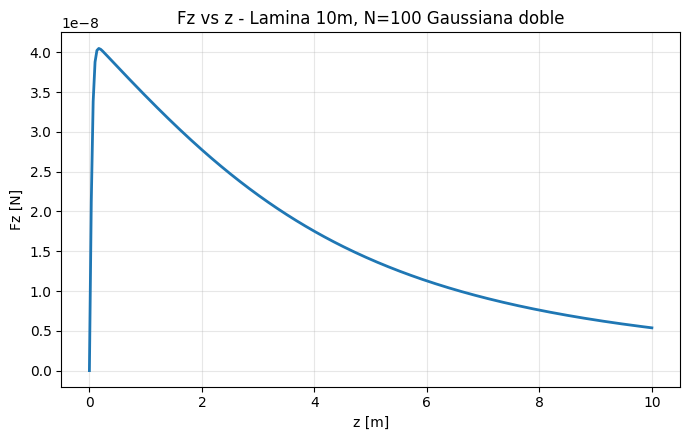

In [125]:
#FASE 4 Calculo y grafico Fz vs z 
#Evaluo en rango z=0 a 10m 
z_vals = np.linspace(0, 10, 300)  # creo vector de 300 valores de z de 0 a 10 m
F_vals = np.array([Fz(z) for z in z_vals])  # calculo Fz para cada z del vector
plt.figure(figsize=(7,4.5))  # creo figura nueva
plt.plot(z_vals, F_vals, linewidth=2)  # grafico curva Fz vs z
plt.xlabel('z [m]')  # etiqueto eje x
plt.ylabel('Fz [N]')  # etiqueto eje y
plt.title('Fz vs z - Lamina 10m, N=100 Gaussiana doble')  # pongo titulo
plt.grid(True, alpha=0.3)  # activo cuadricula
plt.tight_layout()  # ajusto margenes
plt.show()  # grafica

 Este cálculo puede considerarse como un modelo de la atracción gravitacional de una galaxia. La mayor parte de la masa de una galaxia espiral como la Vía Láctea se encuentra en un plano o disco delgado que pasa por el centro galáctico, y la atracción gravitacional ejercida por ese plano sobre cuerpos fuera de la galaxia se puede calcular con los métodos que hemos empleado aquí.

#### (c) Artefacto numérico en $z \to 0$

Debería observarse una curva suave, excepto en valores muy pequeños de $z$, donde la fuerza cae repentinamente a cero. Esta caída no es un efecto físico real , es un artefacto numérico.

**Origen del artefacto -  Errores numéricos:**

La fórmula utilizada es:
$$ F_z = G \sigma z \cdot I(z), \quad I(z)=\int_{-L/2}^{L/2}\int_{-L/2}^{L/2} \frac{dx dy}{(x^2+y^2+z^2)^{3/2}} $$

1.  **Producto $0 \times \infty$:** Cuando $z \to 0$, $z \to 0$ pero $I(z) \to \infty$ porque el integrando en $(0,0)$ es $1/z^3$. Analíticamente:
    $$ \lim_{z\to 0} z \cdot I(z) = \text{constante finita} $$
    Físicamente corresponde a $2\pi G\sigma$ para una lámina infinita. Numéricamente, al implementar `if z<1e-12 return 0`, se fuerza $0 \times \text{grande} = 0$.

2.  **Cuadratura no resuelve el pico:** Gauss-Legendre $N=100$ tiene separación entre nodos $\Delta x \approx L/N = 0.1\, \text{m}$. El pico del integrando tiene un ancho $\sim z$. Si $z < \Delta x$, el pico queda entre nodos y no es muestreado. La integral es subestimada.

**Estrategias para eliminarlo o disminuirlo:**

**1. Evitar $z=0$ - más simple y físicamente correcta:**
Una lámina de espesor cero no tiene sentido físico evaluar justo en $z=0$. Una galaxia tiene espesor.
$$ z \in [0.01, 10]\, \text{m} \quad \text{en lugar de} \quad [0, 10] $$

**2. Cuadratura adaptativa:**
Aumentar $N$ solo cerca de la singularidad.
- Si $z < 0.2\, \text{m}$ uso $N=300$, si no $N=100$.
- Que es sobre lo de Integrales múltiples adaptativas.

**3. Método híbrido - Partir la integral y usar polares en el núcleo:**
Extraigo un cuadrado pequeño $[-a,a]^2$ alrededor de $(0,0)$ y lo integro analíticamente en polares, donde el jacobiano $r$ mata la singularidad:
$$ dx dy = r dr d\theta, \quad \int \frac{r dr}{(r^2+z^2)^{3/2}} = \frac{1}{z} - \frac{1}{\sqrt{a^2+z^2}} $$
El resto del dominio se integra con Gauss normal.

**4. Regularización física:**
Añadir espesor $\epsilon$ que simula espesor real de disco galáctico:
$$ \frac{1}{(x^2+y^2+z^2+\epsilon^2)^{3/2}} $$

**5. Fórmula analítica exacta del rectángulo:**
Para un rectángulo existe solución cerrada:
$$ F_z = G\sigma \sum_{i,j} (-1)^{i+j} \arctan\left(\frac{x_i y_j}{z\sqrt{x_i^2+y_j^2+z^2}}\right), \quad x_i,y_j=\pm L/2 $$
Se puede usar para corregir los puntos con $z<0.1\, \text{m}$.

> **Conclusión para este modelo de galaxia:** El artefacto se elimina empezando en $z=\epsilon>0$ o implementando cuadratura partida con núcleo analítico en coordenadas polares. El modelo de disco delgado sigue siendo válido para $z > 0.1\, \text{m}$.

### 6. Rejilla de difracción

Luz $\lambda$ incide sobre rejilla de ancho $w$, pasa por lente $f$ y llega a pantalla a distancia $x$ del centro.

Intensidad en pantalla:
$$ I(x) = \left| \int_{-w/2}^{w/2} \sqrt{q(u)} e^{i 2\pi x u / \lambda f} du \right|^2 $$

$q(u)$ = transmisión de la rejilla (fracción de luz que deja pasar) a distancia $u$ del centro.

**(a)** Para $q(u)=\sin^2(\alpha u)$, ¿cuánto vale la separación entre rendijas en función de $\alpha$?

alpha = 1.571e+05 rad/m para d=20um
w = 200.0 um


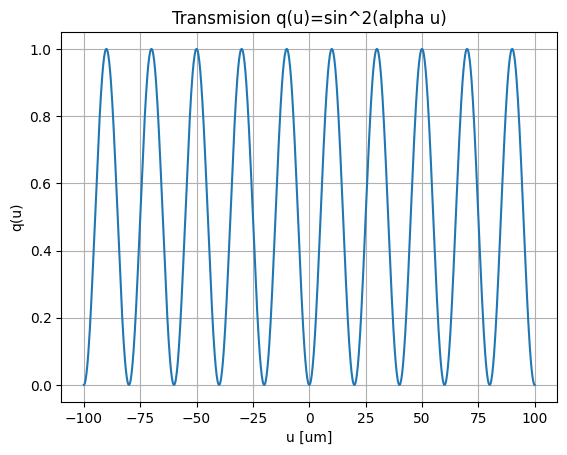

In [126]:
import numpy as np  # importo numpy para calculo numerico
import matplotlib.pyplot as plt  # importo pyplot para graficar
from IPython.display import Image, display  # importo display para mostrar imagen en notebook

#  FASE 1: Defino separacion y calculo alpha 
#Analizo periodicidad de sin^2(alpha u).
d = 20e-6  # defino separacion entre rendijas de 20 micras en metros
alpha = np.pi / d  # calculo alpha = pi / d a partir de periodo
print(f"alpha = {alpha:.3e} rad/m para d=20um")  # imprimo valor de alpha

# --- FASE 2: Defino ancho total para 10 rendijas ---

N_rendijas = 10  # defino numero de rendijas
w = N_rendijas * d  # calculo ancho total w = N * d
print(f"w = {w*1e6} um")  # imprimo ancho en micras

# FASE 3: Defino funcion q(u) = sin^2(alpha u) 
#Creo funcion de transmision 
def q(u):  # defino funcion q(u)
    return np.sin(alpha * u)**2  # regreso sin^2(alpha u)

# FASE 4: Visualizo rejilla q(u) 
# Verifico que maximos esten separados d=pi/alpha. 
u = np.linspace(-w/2, w/2, 1000)  # creo 1000 puntos u entre -w/2 y w/2
plt.figure()  # creo figura
plt.plot(u*1e6, q(u))  # grafico q(u) vs u en micras
plt.xlabel('u [um]'); plt.ylabel('q(u)'); plt.title('Transmision q(u)=sin^2(alpha u)'); plt.grid(True); plt.show() 


**(b)** Hacer función Python `q(u)` para $q(u)=\sin^2(\alpha u)$ con separación de $20\,\mu m$ entre rendijas.

d = 20.0 um, alpha = pi/d = 1.571e+05 rad/m
q(u) en puntos de prueba: [5.99903913e-32 1.49975978e-32 0.00000000e+00 1.49975978e-32
 5.99903913e-32]


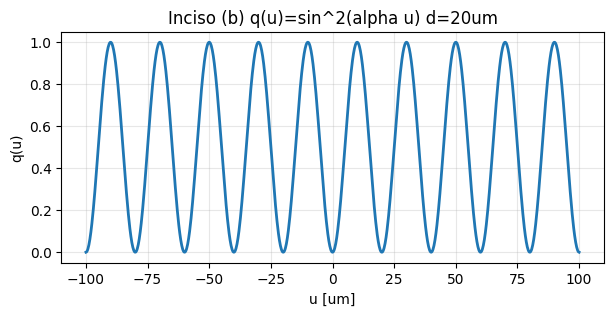

In [127]:
import numpy as np  # importo numpy para calculo numerico
import matplotlib.pyplot as plt  # importo pyplot para graficar

# FASE 1: Calculo alpha a partir de la separacion 
# Del inciso (a) obtengo d = pi/alpha => alpha = pi/d. Necesito alpha para definir q(u).
d = 20e-6  # defino separacion entre rendijas de 20 micras en metros
alpha = np.pi / d  # calculo alpha = pi / d
print(f"d = {d*1e6} um, alpha = pi/d = {alpha:.3e} rad/m")  # imprimo valores

# --- FASE 2: Defino funcion de transmision q(u) = sin^2(alpha u) ---
# Creo funcion reutilizable . Esta q(u) es la que va dentro de la integral de I(x).
def q(u):  # defino funcion q(u) que devuelve transmision
    return np.sin(alpha * u)**2  # calculo y regreso sin^2(alpha * u)

#FASE 3Pruebo la funcion y verifico periodicidad 
#Verifico que q(u) tiene maximos cada 20um 
u_test = np.array([-40e-6, -20e-6, 0, 20e-6, 40e-6])  # creo 5 puntos de prueba separados 20um
print(f"q(u) en puntos de prueba: {q(u_test)}")  # imprimo valores de q, deben ser 0 en multiplos de pi/alpha

# Grafico q(u) para visualizar 10 rendijas
w = 10 * d  # calculo ancho total para 10 rendijas = 200 um
u = np.linspace(-w/2, w/2, 1000)  # creo 1000 puntos u entre -w/2 y w/2
plt.figure(figsize=(7,3))  # creo figura
plt.plot(u*1e6, q(u), linewidth=2)  # grafico q(u) vs u en micras
plt.xlabel('u [um]'); plt.ylabel('q(u)'); plt.title('Inciso (b) q(u)=sin^2(alpha u) d=20um'); plt.grid(True, alpha=0.3); plt.show() 

**(c)** Utiliza tu función en un programa para calcular y representar gráficamente la intensidad del patrón de difracción producido por dicha rejilla con diez rendijas en total, si la luz incidente tiene una longitud de onda $\lambda = 500\, \text{nm}$. Supongamos que la lente tiene una distancia focal de $1$ metro y la pantalla tiene $10\, \text{cm}$ de ancho. Puedes utilizar cualquier método que creas apropiado para hacer la integral. Una vez que hayas hecho tu elección, también deberás decidir la cantidad de puntos de muestra que utilizarás. ¿Qué criterios influyen en esta decisión?

 Observa que el integrando en la ecuación para $I(x)$ es un valor complejo, por lo que tendrás que usar variables complejas en tu programa.

In [128]:
import numpy as np  
import matplotlib.pyplot as plt  

In [129]:
# FASE 1: Defino parametros fisicos
# Paso todo a SI. Defino geometria de rejilla y sistema optico.
d = 20e-6  # defino separacion entre rendijas 20 micras
alpha = np.pi / d  # calculo alpha = pi/d 
N_rendijas = 10  # defino 10 rendijas en total
w = N_rendijas * d  # calculo ancho total w = 200 um
lam = 500e-9  # defino longitud de onda 500 nm
f = 1.0  # defino distancia focal 1 m
screen_width = 0.10  # defino ancho de pantalla 10 cm

In [130]:
# FASE 2 Decido puntos de muestra
#  Necesito resolver dos escalas: periodo de rejilla 20um y oscilacion del integrando e^{i2pixu/lambda f}.
# Para x_max=5cm, periodo en u = lambda f / x = 500e-9*1/0.05 = 10um. Necesito du < 10um/10 = 1um para 10 puntos por oscilacion.
# Elijo du=0.1um => N_u=2000. Para x, necesito resolver pico central ancho ~ lambda f / w = 2.5mm, asi que dx=0.125mm => N_x=800.
N_u = 2000  # defino 2000 puntos en u para integral
N_x = 800  # defino 800 puntos en x en pantalla
u = np.linspace(-w/2, w/2, N_u)  # creo vector u de -w/2 a w/2
x = np.linspace(-screen_width/2, screen_width/2, N_x)  # creo vector x en pantalla

In [131]:
# FASE 3: Defino transmision y amplitud 
# Justificacion: q(u)=sin^2(alpha u) es intensidad, amplitud es sqrt(q)=|sin(alpha u)|. Necesito valor complejo.
def q(u):  # defino funcion q(u)
    return np.sin(alpha * u)**2  # regreso sin^2(alpha u)
amp = np.sqrt(q(u))  # calculo amplitud sqrt(q) = |sin|
# amp = np.abs(np.sin(alpha*u)) # alternativa mas estable

In [132]:
#  FASE 4: Calculo integral compleja I(x) 
# Justificacion: Uso metodo del trapecio para integral compleja. Formula I(x)=|int amp*exp(i2pixu/lambda f) du|^2. 
k_factor = 2*np.pi / (lam * f)  # calculo factor 2pi / lambda f
I = np.zeros(N_x)  # creo arreglo para intensidad
for i, xi in enumerate(x):  # recorro cada posicion x en pantalla
    phase = np.exp(1j * k_factor * xi * u)  # calculo fase compleja e^{i2pixu/lambda f}
    integrand = amp * phase  # multiplico amplitud por fase
    integral = np.trapezoid(integrand, u)  # integro con trapecio sobre u
    I[i] = np.abs(integral)**2  # calculo modulo al cuadrado para intensidad

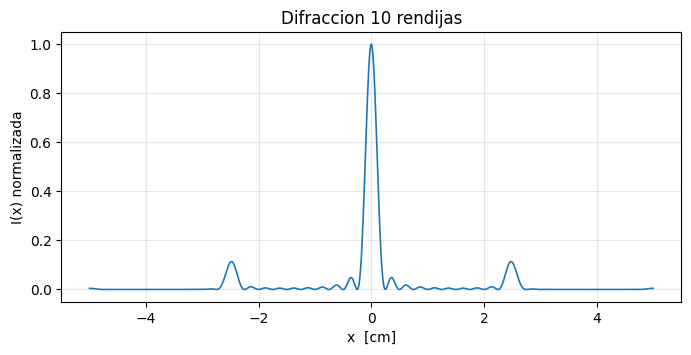

In [141]:
# FASE 5: Grafico intensidad
#  Normalizo y grafico
I_norm = I / np.max(I)  # normalizo intensidad a max=1
plt.figure(figsize=(8,3.5))  # creo figura
plt.plot(x*100, I_norm, linewidth=1.2)  # grafico I vs x en cm
plt.xlabel('x  [cm]'); plt.ylabel('I(x) normalizada'); plt.title('Difraccion 10 rendijas'); plt.grid(True, alpha=0.3); plt.show()  

**(d)** Crea una visualización de cómo se vería el patrón de difracción en la pantalla usando un gráfico de densidad. Tu gráfico debería verse similar a franjas brillantes de difracción sobre fondo oscuro.

In [134]:

# --- FASE 1: Reutilizo parametros del inciso (c)
# Uso misma rejilla 10 rendijas d=20um, lambda=500nm, f=1m, pantalla 10cm.
d = 20e-6  # defino separacion 20um
alpha = np.pi / d  # calculo alpha = pi/d
N_rendijas = 10  # defino 10 rendijas
w = N_rendijas * d  # calculo ancho total 200um
lam = 500e-9  # defino lambda 500nm
f = 1.0  # defino focal 1m
screen_width = 0.10  # defino ancho pantalla 10cm
N_u = 2000  # defino 2000 puntos en u (criterio Nyquist)
N_x = 800  # defino 800 puntos en x

In [135]:
# FASE 2Construyo dominios de integracion 
#  Discretizo u en rejilla y x en pantalla.
u = np.linspace(-w/2, w/2, N_u)  # creo vector u de -w/2 a w/2
x = np.linspace(-screen_width/2, screen_width/2, N_x)  # creo vector x en pantalla

In [136]:
#FASE 3: Defino amplitud y calculo I(x)
# Calculo I(x)=|int sqrt(q) e^{i2pixu/lambda f} du|^2 con integral compleja.
def q(u):  # defino transmision q(u)
    return np.sin(alpha * u)**2  # regreso sin^2(alpha u)
amp = np.sqrt(q(u))  # calculo amplitud sqrt(q) = |sin(alpha u)|
k_factor = 2*np.pi / (lam * f)  # calculo factor 2pi/lambda f
I = np.zeros(N_x)  # creo arreglo para intensidad
for i, xi in enumerate(x):  # recorro cada posicion x en pantalla
    phase = np.exp(1j * k_factor * xi * u)  # calculo fase compleja e^{i2pixu/lambda f}
    integrand = amp * phase  # multiplico amplitud por fase
    # Uso trapezoid para numpy 2.0, trapz para 1.x - elige el que no te de error
    try:
        integral = np.trapezoid(integrand, u)  # intento con trapezoid (numpy 2.0)
    except AttributeError:
        integral = np.trapz(integrand, u)  # si falla uso trapz (numpy 1.x)
    I[i] = np.abs(integral)**2  # calculo modulo al cuadrado

In [137]:
#  FASE 4: Creo imagen 2D para grafico de densidad 
# El patron es 1D en x,
I_norm = I / np.max(I)  # normalizo
I_display = I_norm**0.3  # aplico gamma 0.3 para realzar rayas debiles, si no solo se ven 3
# I_display = np.log1p(10*I_norm)/np.log1p(10)  # alternativa logaritmica
Ny = 100
image = np.tile(I_display, (Ny, 1))

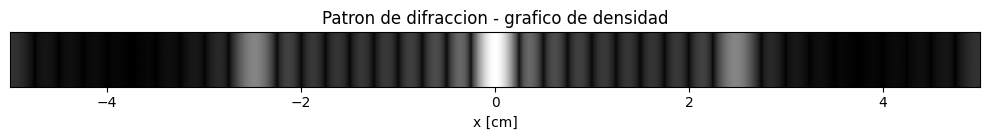

In [140]:
#  FASE 5: Grafico de densidad tipo pantalla 
#  Uso imshow gris para simular luz, como pide imagen del enunciado.
plt.figure(figsize=(10,1.5))  # creo figura alargada tipo pantalla
plt.imshow(image, cmap='gray', aspect='auto', extent=[-screen_width/2*100, screen_width/2*100, 0, 1])  # muestro densidad en escala cm
plt.xlabel('x [cm]')  # etiqueto eje x
plt.title('Patron de difraccion - grafico de densidad')  # pongo titulo
plt.yticks([])  # quito ticks en y
plt.tight_layout()  # ajusto margenes
plt.show()  # grafica

**(e)** Modifica aún más su programa para crear imágenes de los patrones de difracción producidos por rejillas con los siguientes perfiles:

In [142]:

#  Parametros base del sistema
#  Reutilizo mismos lambda, f, pantalla del inciso (c).
d = 20e-6  # defino separacion 20um
alpha = np.pi / d  # calculo alpha = pi/d
beta = alpha / 4  # calculo beta = 1/4 alpha como pide e-i)
w = 10 * d  # ancho total 200um para 10 rendijas
lam = 500e-9  # lambda 500nm
f = 1.0  # focal 1m
screen_width = 0.10  # pantalla 10cm
N_u = 3000  # defino 3000 puntos en u para resolver modulacion fina
N_x = 800  # defino 800 puntos en x
u = np.linspace(-w/2, w/2, N_u)  # creo vector u
x = np.linspace(-screen_width/2, screen_width/2, N_x)  # creo vector x pantalla
k_factor = 2*np.pi / (lam * f)  # calculo factor fase


i. Un perfil de transmisión que obedece a $q(u) = \sin^2 \alpha u \, \sin^2 \beta u$. Con $\alpha$ y $w$ (ancho total de rejilla) igual que antes; y $\beta = \frac{1}{4}\alpha$.

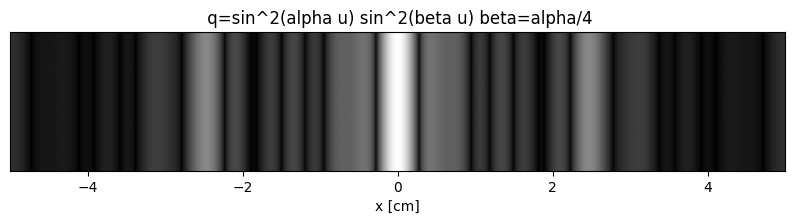

In [144]:
# Modulo la rejilla original con una envolvente mas lenta beta=alpha/4.
def q_i(u):  # defino transmision e-i)
    return np.sin(alpha * u)**2 * np.sin(beta * u)**2  # regreso sin^2(alpha u) sin^2(beta u)
amp_i = np.sqrt(q_i(u))  # calculo amplitud sqrt(q)
I_i = np.zeros(N_x)  # creo arreglo intensidad
for i, xi in enumerate(x):  # recorro cada x
    phase = np.exp(1j * k_factor * xi * u)  # calculo fase compleja
    integrand = amp_i * phase  # multiplico amplitud por fase
    try:
        integral = np.trapezoid(integrand, u)  # integro (numpy 2.0)
    except AttributeError:
        integral = np.trapz(integrand, u)  # integro (numpy 1.x)
    I_i[i] = np.abs(integral)**2  # calculo |integral|^2
I_i_norm = I_i / np.max(I_i)  # normalizo
image_i = np.tile((I_i_norm**0.3), (100,1))  # creo imagen 2D con gamma 0.3 para ver rayas debiles
plt.figure(figsize=(10,1.8)); plt.imshow(image_i, cmap='gray', aspect='auto', extent=[-5,5,0,1]); plt.xlabel('x [cm]'); plt.title(' q=sin^2(alpha u) sin^2(beta u) beta=alpha/4'); plt.yticks([]); plt.show()

ii. Dos rendijas "cuadradas", es decir, rendijas con $100\%$ de transmisión a través de la rendija y $0\%$ de transmisión en cualquier otro lugar. Calcule el patrón de difracción para rendijas no idénticas, una de $10\, \mu\text{m}$ de ancho y la otra de $20\, \mu\text{m}$ de ancho, con un espacio de $60\, \mu\text{m}$ entre las dos.

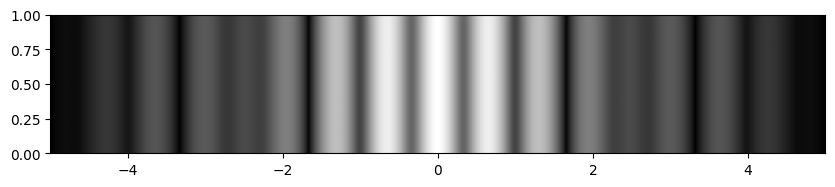

In [145]:
# Dos rendijas cuadradas no identicas
#  Transmision  dentro de rendija, nadafuera. Defino rendija 10um y 20um con gap 60um entre bordes.
# Coloco gap centrado: rendija1 de -40um a -30um (10um ancho), rendija2 de 30um a 50um (20um ancho). Gap entre -30um y 30um = 60um.
w_ii = 100e-6  # defino ancho total 200um para contener ambas rendijas
u2 = np.linspace(-w_ii, w_ii, 4000)  # creo vector u2 mas fino para bordes cuadrados
def q_ii(u):  # defino transmision cuadrada
    cond1 = (u >= -40e-6) & (u <= -30e-6)  # verifico si u esta en rendija 1
    cond2 = (u >= 30e-6) & (u <= 50e-6)  # verifico si u esta en rendija 2
    return (cond1 | cond2).astype(float)  # regreso 1 si esta en alguna rendija, 0 si no
amp_ii = q_ii(u2)  # amplitud = q porque q es 0 o 1
I_ii = np.zeros(N_x)  # creo arreglo intensidad
for i, xi in enumerate(x):  # recorro cada x
    phase = np.exp(1j * k_factor * xi * u2)  # calculo fase
    integrand = amp_ii * phase  # multiplico
    try:
        integral = np.trapezoid(integrand, u2)  # integro
    except AttributeError:
        integral = np.trapz(integrand, u2)  # integro
    I_ii[i] = np.abs(integral)**2  # |integral|^2
I_ii_norm = I_ii / np.max(I_ii)  # normalizo
image_ii = np.tile((I_ii_norm**0.4), (100,1))  # creo imagen 2D con gamma 0.4
plt.figure(figsize=(10,1.8)); plt.imshow(image_ii, cmap='gray', aspect='auto', extent=[-5,5,0,1])

Para el inciso e-i) al multiplicar por $\sin^2(\beta u)$ con $\beta=\alpha/4$ se modula la intensidad y aparecen órdenes faltantes. Y para e-ii) con dos rendijas cuadradas no idénticas de 10um y 20um separadas 60um, el patrón ya no es simétrico perfecto y la envolvente es más ancha porque las rendijas son más angostas.